Tamaño: (120, 120)
Modo: RGB


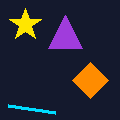

In [51]:

from PIL import Image, ImageDraw, ImageEnhance, ImageFilter
import numpy as np
from skimage import color, filters

img = Image.new("RGB", (120, 120), (20, 25, 45))
draw = ImageDraw.Draw(img)

draw.polygon(
    [(25, 8), (29, 19), (41, 19), (31, 26), (35, 38),
     (25, 31), (15, 38), (19, 26), (9, 19), (21, 19)],
    fill=(255, 230, 0)
)

draw.polygon(
    [(65, 15), (48, 48), (82, 48)],
    fill=(160, 60, 220)
)

draw.polygon(
    [(90, 62), (108, 80), (90, 98), (72, 80)],
    fill=(255, 140, 0)
)

draw.line(
    [(8, 105), (55, 112)],
    fill=(0, 220, 255),
    width=4
)

print("Tamaño:", img.size)
print("Modo:", img.mode)

display(img)
img.save("mi_imagen.png")


In [45]:

img = Image.open("mi_imagen.png")

print("Formato:", img.format)
print("Tamaño:", img.size)
print("Modo:", img.mode)

fondo = (5, 5)
estrella = (25, 24)
triangulo = (65, 35)
rombo = (90, 80)

print("Fondo:", img.getpixel(fondo))
print("Estrella:", img.getpixel(estrella))
print("Triángulo:", img.getpixel(triangulo))
print("Rombo:", img.getpixel(rombo))

Formato: PNG
Tamaño: (120, 120)
Modo: RGB
Fondo: (20, 25, 45)
Estrella: (255, 230, 0)
Triángulo: (160, 60, 220)
Rombo: (255, 140, 0)


Tamaño gris: (120, 120)
Tamaño rotado: (120, 120)
Tamaño reducido: (60, 60)
Tamaño volteado: (120, 120)


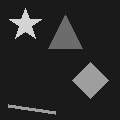

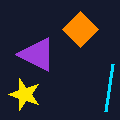

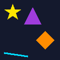

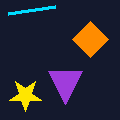

In [46]:

gris = img.convert("L")
print("Tamaño gris:", gris.size)

rotada = img.rotate(90, expand=True)
print("Tamaño rotado:", rotada.size)

reducida = img.resize((60, 60))
print("Tamaño reducido:", reducida.size)

volteada = img.transpose(
    Image.Transpose.FLIP_TOP_BOTTOM
)
print("Tamaño volteado:", volteada.size)

gris.save("imagen_gris.png")
rotada.save("imagen_rotada.png")
reducida.save("imagen_reducida.png")
volteada.save("imagen_volteada.png")

display(gris)
display(rotada)
display(reducida)
display(volteada)

Antes: (255, 140, 0)
Después: (255, 255, 0)
¿Hay un canal en 255?: True
¿Hay un canal en 0?: True


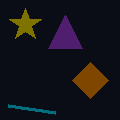

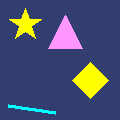

In [47]:
img = Image.open("mi_imagen.png")

brillo_bajo = ImageEnhance.Brightness(img).enhance(0.5)

brillo_alto = ImageEnhance.Brightness(img).enhance(2.5)

# Consultar el píxel naranja antes y después
antes = img.getpixel((90, 80))
despues = brillo_alto.getpixel((90, 80))

print("Antes:", antes)
print("Después:", despues)

print("¿Hay un canal en 255?:",
      any(c == 255 for c in despues))

print("¿Hay un canal en 0?:",
      any(c == 0 for c in despues))

brillo_bajo.save("brillo_bajo.png")
brillo_alto.save("brillo_alto.png")

display(brillo_bajo)
display(brillo_alto)

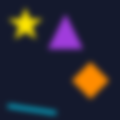

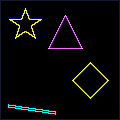

In [48]:
desenfoque = img.filter(
    ImageFilter.GaussianBlur(radius=3)
)

bordes = img.filter(ImageFilter.FIND_EDGES)

desenfoque.save("imagen_blur.png")
bordes.save("imagen_bordes.png")

display(desenfoque)
display(bordes)

In [49]:
img_rgb = np.array(img)

gris_skimage = color.rgb2gray(img_rgb)
gris_pillow = np.array(img.convert("L"))

x, y = 5, 5

valor_pillow = gris_pillow[y, x]
valor_skimage = gris_skimage[y, x] * 255

print("Pillow:", valor_pillow)
print("scikit-image x 255:", valor_skimage)
print(
    "Diferencia:",
    abs(float(valor_pillow) - float(valor_skimage))
)

Pillow: 26
scikit-image x 255: 25.379499999999997
Diferencia: 0.6205000000000034


Umbral de Otsu: 0.36461361825980393
Proporción True: 0.08381944444444445
Porcentaje True: 8.381944444444445 %


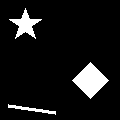

In [50]:
umbral = filters.threshold_otsu(gris_skimage)
imagen_binaria = gris_skimage > umbral

proporcion_true = np.mean(imagen_binaria)

print("Umbral de Otsu:", umbral)
print("Proporción True:", proporcion_true)
print("Porcentaje True:", proporcion_true * 100, "%")

# Guardar y mostrar la imagen binaria
binaria_pillow = Image.fromarray(
    (imagen_binaria * 255).astype(np.uint8)
)

binaria_pillow.save("imagen_otsu.png")
display(binaria_pillow)